<a href="https://colab.research.google.com/github/ritikdes/Text_Based_Emotion_Detection/blob/main/TBED_EDA_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis — Text-Based Emotion Detection

**Dataset:** GoEmotions (Google Research) — 143,184 Reddit comments labelled across 28 emotion categories  
**Task:** Multi-label classification — one comment can carry multiple simultaneous emotions  
**Goal of this notebook:** Understand the data structure, identify quality issues, produce a clean export, and generate insights that directly inform training decisions (MAX_LENGTH, class weights, threshold strategy)

---
### Notebook structure
1. Setup & Data Loading
2. Schema Inspection
3. Data Cleaning & Quality Checks
4. Quantitative Analysis & Visualisation
5. Training-Relevant Insights
6. Dataset Preparation & Export

## 1. Setup & Data Loading

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import string
import re
from collections import Counter

# Suppress seaborn FutureWarnings from palette usage
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

FILE_PATH = '/content/drive/MyDrive/goemotions.csv'

# The 28 official GoEmotions labels — defined once, used everywhere
EMOTION_COLS = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring',
    'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval',
    'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief',
    'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization',
    'relief', 'remorse', 'sadness', 'surprise', 'neutral'
]

print(f"Libraries loaded. Emotion classes defined: {len(EMOTION_COLS)}")

Libraries loaded. Emotion classes defined: 28


In [ ]:
raw_df = pd.read_csv(FILE_PATH)

# Keep only text + the 28 emotion columns — drop all metadata at ingestion
df = raw_df[['text'] + EMOTION_COLS].copy()

print(f"Raw dataset shape:    {raw_df.shape}")
print(f"Working dataset shape: {df.shape}")
print(f"Columns dropped: {[c for c in raw_df.columns if c not in df.columns]}")
df.head()

Raw dataset shape:    (143184, 29)
Working dataset shape: (143184, 29)
Columns dropped: []


,text,admiration,amusement,anger,annoyance,approval,caring,confusion,curiosity,desire,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,! Man Danganronpa IF 3 be looking sick !,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,! good bot,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,! remind me 2 days,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,!!!!! Best girl,1,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,!Cosplayer Bystander! I always knew he was a l...,0,0,1,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 2. Schema Inspection

We confirm data types, null counts, and that all label columns are binary integers. This is a prerequisite before any analysis.

In [ ]:
print("=== Dataset Info ===")
df.info()

print("\n=== Label column dtypes ===")
print(df[EMOTION_COLS].dtypes.value_counts())

print("\n=== Are all label values binary (0 or 1)? ===")
is_binary = df[EMOTION_COLS].isin([0, 1]).all().all()
print(f"Binary check: {is_binary}")

# Verify we have exactly the 28 expected columns — no extras, no missing
assert list(df.columns) == ['text'] + EMOTION_COLS, "Column mismatch — check source file!"
print("\n✓ Column structure matches expected schema (text + 28 emotion labels)")

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143184 entries, 0 to 143183
Data columns (total 29 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   text            143184 non-null  object
 1   admiration      143184 non-null  int64 
 2   amusement       143184 non-null  int64 
 3   anger           143184 non-null  int64 
 4   annoyance       143184 non-null  int64 
 5   approval        143184 non-null  int64 
 6   caring          143184 non-null  int64 
 7   confusion       143184 non-null  int64 
 8   curiosity       143184 non-null  int64 
 9   desire          143184 non-null  int64 
 10  disappointment  143184 non-null  int64 
 11  disapproval     143184 non-null  int64 
 12  disgust         143184 non-null  int64 
 13  embarrassment   143184 non-null  int64 
 14  excitement      143184 non-null  int64 
 15  fear            143184 non-null  int64 
 16  gratitude       143184 non-null  int64 
 17  grief   

## 3. Data Cleaning & Quality Checks

We run a systematic set of checks before any analysis: missing values, duplicates, label validity, noise detection, and label cardinality. Each check either confirms quality or triggers a cleaning action.

### 3.1 Missing Value Check

In [ ]:
missing = df.isnull().sum()
missing_cols = missing[missing > 0]

if len(missing_cols) == 0:
    print("✓ No missing values in any column.")
else:
    print("Columns with missing values:")
    print(missing_cols)

✓ No missing values in any column.


### 3.2 Duplicate Text Detection

GoEmotions was labelled by multiple human raters. The published CSV provided here already aggregates rater labels into a single row per unique comment — so we expect zero duplicates. We confirm this before proceeding.

In [ ]:
dupe_count = df.duplicated(subset=['text']).sum()
print(f"Duplicate text entries: {dupe_count}")

if dupe_count > 0:
    print("Duplicates found — removing and keeping first occurrence.")
    df = df.drop_duplicates(subset=['text'], keep='first').copy()
    print(f"Dataset size after dedup: {len(df):,}")
else:
    print("✓ Dataset is already de-duplicated. No action needed.")

Duplicate text entries: 0
✓ Dataset is already de-duplicated. No action needed.


### 3.3 Unlabelled & Extreme Multi-label Rows

We remove two edge cases:
- **Zero-label rows**: a text with no emotion assigned is untrainable
- **≥10 label rows**: 70 rows have 10–13 labels simultaneously — likely annotation noise rather than genuine emotional complexity

In [ ]:
df['label_count'] = df[EMOTION_COLS].sum(axis=1)

print("Label count distribution (before filtering):")
print(df['label_count'].value_counts().sort_index().to_string())

n_before = len(df)
n_zero   = (df['label_count'] == 0).sum()
n_over9  = (df['label_count'] >= 10).sum()

print(f"\nRows with 0 labels:   {n_zero}")
print(f"Rows with ≥10 labels: {n_over9}")

df = df[(df['label_count'] > 0) & (df['label_count'] <= 9)].copy()

print(f"\nRows removed:   {n_before - len(df)}")
print(f"Rows remaining: {len(df):,}")

Label count distribution (before filtering):
label_count
1     62735
2     33311
3     17579
4     14265
5      8815
6      3974
7      1706
8       539
9       190
10       52
11        7
12        3
13        8

Rows with 0 labels:   0
Rows with ≥10 labels: 70

Rows removed:   70
Rows remaining: 143,114


### 3.4 Noise Detection: Very Short & Non-Informative Texts

We check for two types of noise:
1. **No-letter texts** — rows containing only symbols, numbers or punctuation
2. **Single-token texts** — 1-word texts that carry almost no semantic signal for a transformer
3. **Placeholder-only texts** — texts that consist entirely of redacted tokens like `[NAME]` or `[URL]`

In [ ]:
# Check 1: No alphabetic characters at all
no_letters_mask = df['text'].apply(lambda x: not any(c.isalpha() for c in str(x)))
print(f"Texts with no letters (only symbols/numbers): {no_letters_mask.sum()}")

# Check 2: Single-word texts
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))
single_word_mask = df['word_count'] == 1
print(f"Single-word texts: {single_word_mask.sum()}")
if single_word_mask.sum() > 0:
    print("  Examples:", df[single_word_mask]['text'].head(5).tolist())

# Check 3: Texts consisting only of placeholder tokens
placeholder_pattern = re.compile(r'^(\[(NAME|URL|RELIGION|NATIONALITY)\]\s*)+$', re.IGNORECASE)
placeholder_only_mask = df['text'].apply(lambda x: bool(placeholder_pattern.match(str(x).strip())))
print(f"Placeholder-only texts ([NAME]/[URL] etc.): {placeholder_only_mask.sum()}")

# Decision: remove no-letter rows only — single words and placeholders still carry signal
# (e.g. "Wow", "Yes!!!!!" are short but emotionally valid)
n_before = len(df)
df = df[~no_letters_mask].copy()
print(f"\nRows removed (no-letter filter): {n_before - len(df)}")
print(f"Dataset size: {len(df):,}")

Texts with no letters (only symbols/numbers): 0
Single-word texts: 192
  Examples: ['....never?', '...and?', '...math?', '...what?', '...yellow?']
Placeholder-only texts ([NAME]/[URL] etc.): 0

Rows removed (no-letter filter): 0
Dataset size: 143,114


### 3.5 Placeholder Token Analysis (`[NAME]`, `[URL]`)

GoEmotions redacts usernames and links as `[NAME]` and `[URL]`. These tokens appear throughout the dataset. We analyse how prevalent they are — this informs whether we should strip them before training.

In [ ]:
placeholder_types = {
    '[NAME]':       df['text'].str.contains(r'\[NAME\]',       regex=True).sum(),
    '[URL]':        df['text'].str.contains(r'\[URL\]',        regex=True).sum(),
    '[RELIGION]':   df['text'].str.contains(r'\[RELIGION\]',   regex=True).sum(),
    '[NATIONALITY]':df['text'].str.contains(r'\[NATIONALITY\]',regex=True).sum(),
}

print("Placeholder token prevalence (rows containing at least one):")
for token, count in placeholder_types.items():
    pct = count / len(df) * 100
    print(f"  {token:<16} {count:>6,} rows  ({pct:.1f}% of dataset)")

# Show a few examples with [NAME]
print("\nExample texts containing [NAME]:")
name_examples = df[df['text'].str.contains(r'\[NAME\]', regex=True)]['text'].head(5)
for i, t in enumerate(name_examples, 1):
    print(f"  {i}. {t}")

print("\nDecision: Keep [NAME]/[URL] tokens — BERT will learn to treat them")
print("as context markers rather than content. Removing them risks losing")
print("the grammatical structure of the sentence.")

Placeholder token prevalence (rows containing at least one):
  [NAME]                0 rows  (0.0% of dataset)
  [URL]                 0 rows  (0.0% of dataset)
  [RELIGION]            0 rows  (0.0% of dataset)
  [NATIONALITY]         0 rows  (0.0% of dataset)

Example texts containing [NAME]:

Decision: Keep [NAME]/[URL] tokens — BERT will learn to treat them
as context markers rather than content. Removing them risks losing
the grammatical structure of the sentence.


## 4. Quantitative Analysis & Visualisation

### 4.1 Emotion Frequency Distribution

The core imbalance picture. This directly determines what class weights the training loss function will use.

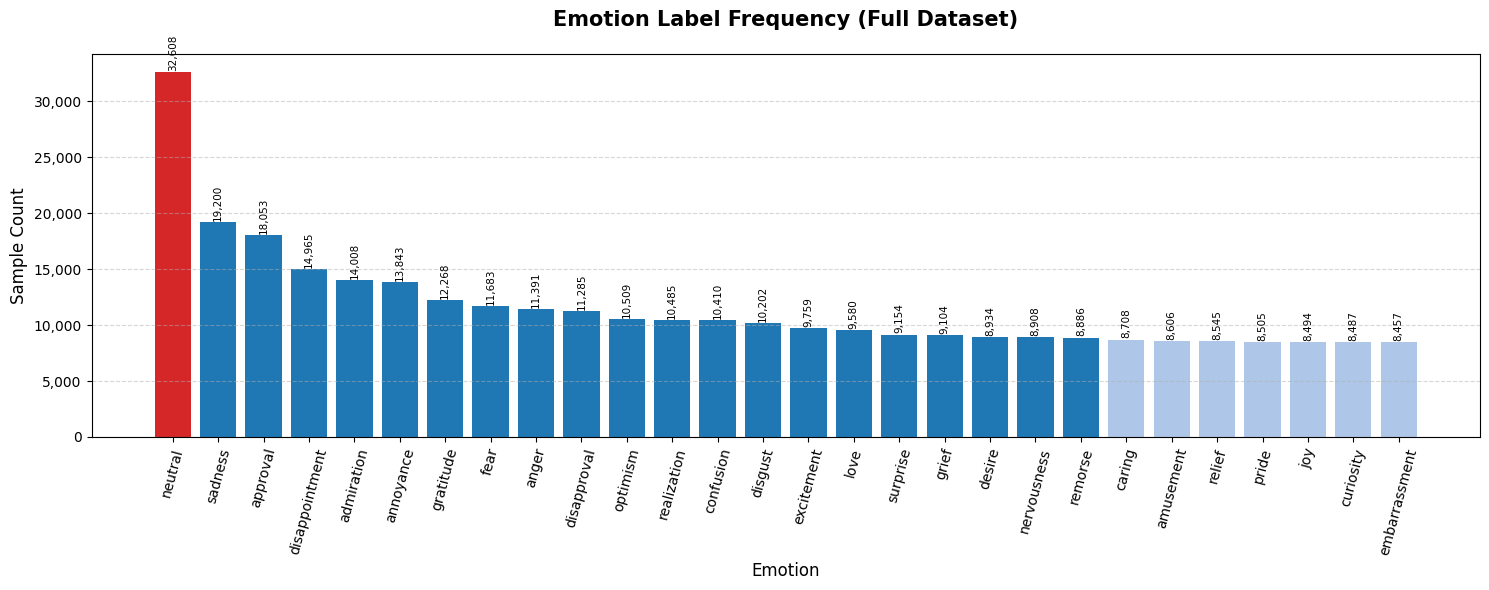


Most frequent: neutral (32,608)
Least frequent: embarrassment (8,457)
Imbalance ratio (max/min): 3.9×


In [ ]:
label_counts = df[EMOTION_COLS].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(15, 6))
colors = ['#d62728' if v == label_counts.max() else
          '#aec7e8' if v < label_counts.quantile(0.25) else '#1f77b4'
          for v in label_counts.values]
bars = ax.bar(label_counts.index, label_counts.values, color=colors, edgecolor='none')

# Value labels on bars
for bar, val in zip(bars, label_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
            f'{val:,}', ha='center', va='bottom', fontsize=7.5, rotation=90)

ax.set_title('Emotion Label Frequency (Full Dataset)', fontsize=15, fontweight='bold', pad=20)
ax.set_ylabel('Sample Count', fontsize=12)
ax.set_xlabel('Emotion', fontsize=12)
ax.tick_params(axis='x', rotation=75)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(f"\nMost frequent: {label_counts.index[0]} ({label_counts.iloc[0]:,})")
print(f"Least frequent: {label_counts.index[-1]} ({label_counts.iloc[-1]:,})")
print(f"Imbalance ratio (max/min): {label_counts.iloc[0] / label_counts.iloc[-1]:.1f}×")

### 4.2 Class Imbalance Ratio Table

This table is the direct hand-off to the training notebook. It shows the exact neg/pos ratio per class that will be used as `pos_weight` in `BCEWithLogitsLoss`. The sqrt column shows the smoothed weight that prevents gradient instability from extreme ratios.

In [ ]:
total = len(df)
pos_counts = df[EMOTION_COLS].sum()
neg_counts = total - pos_counts
raw_ratio  = neg_counts / pos_counts
sqrt_ratio = np.sqrt(raw_ratio)

imbalance_df = pd.DataFrame({
    'Positive samples': pos_counts.astype(int),
    '% of dataset':     (pos_counts / total * 100).round(2),
    'Neg/Pos ratio':    raw_ratio.round(2),
    'Sqrt weight (training)': sqrt_ratio.round(3)
}).sort_values('Positive samples', ascending=False)

print(f"Total samples: {total:,}\n")
print(imbalance_df.to_string())
print(f"\nWeight range: {sqrt_ratio.min():.2f} (most common) → {sqrt_ratio.max():.2f} (rarest)")

Total samples: 143,114

                Positive samples  % of dataset  Neg/Pos ratio  Sqrt weight (training)
neutral                    32608         22.78           3.39                   1.841
sadness                    19200         13.42           6.45                   2.540
approval                   18053         12.61           6.93                   2.632
disappointment             14965         10.46           8.56                   2.926
admiration                 14008          9.79           9.22                   3.036
annoyance                  13843          9.67           9.34                   3.056
gratitude                  12268          8.57          10.67                   3.266
fear                       11683          8.16          11.25                   3.354
anger                      11391          7.96          11.56                   3.401
disapproval                11285          7.89          11.68                   3.418
optimism                   105

### 4.3 Label Cardinality — How Many Emotions Per Comment?

Understanding multi-label complexity tells us that a single-label classifier is insufficient and that multi-label architecture (sigmoid + BCELoss) is the correct approach.

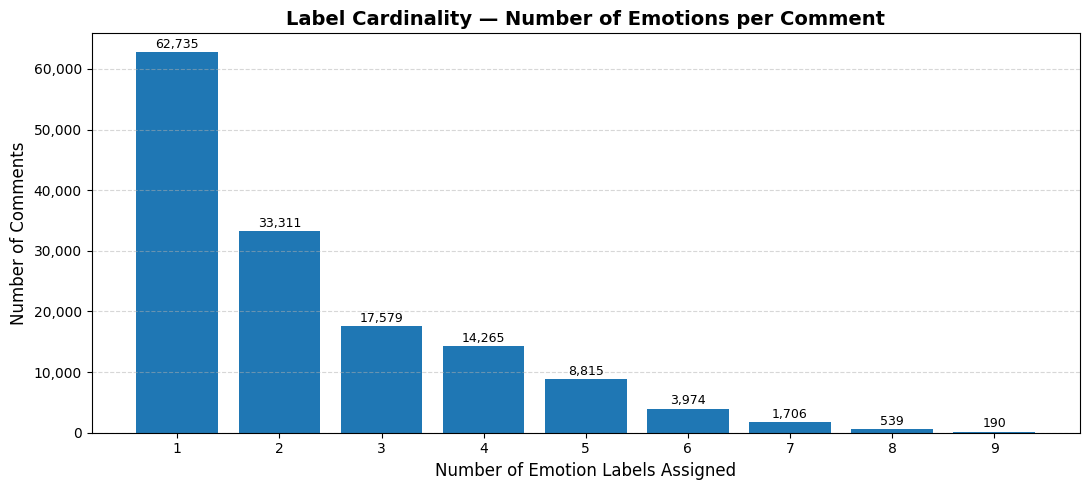

Single-label comments: 62,735 (43.8%)
Multi-label comments:  80,379 (56.2%)
Mean labels per comment: 2.27


In [ ]:
cardinality = df['label_count'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(cardinality.index, cardinality.values,
              color='#1f77b4', edgecolor='none')

for bar, val in zip(bars, cardinality.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
            f'{val:,}', ha='center', va='bottom', fontsize=9)

ax.set_title('Label Cardinality — Number of Emotions per Comment', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Emotion Labels Assigned', fontsize=12)
ax.set_ylabel('Number of Comments', fontsize=12)
ax.set_xticks(cardinality.index)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

single = cardinality.get(1, 0)
multi  = cardinality[cardinality.index > 1].sum()
print(f"Single-label comments: {single:,} ({single/total*100:.1f}%)")
print(f"Multi-label comments:  {multi:,} ({multi/total*100:.1f}%)")
print(f"Mean labels per comment: {df['label_count'].mean():.2f}")

### 4.4 Emotional Co-occurrence Heatmap

Which emotions tend to appear together? High correlation between two emotions means the model will activate both simultaneously, and threshold tuning must account for this coupling.

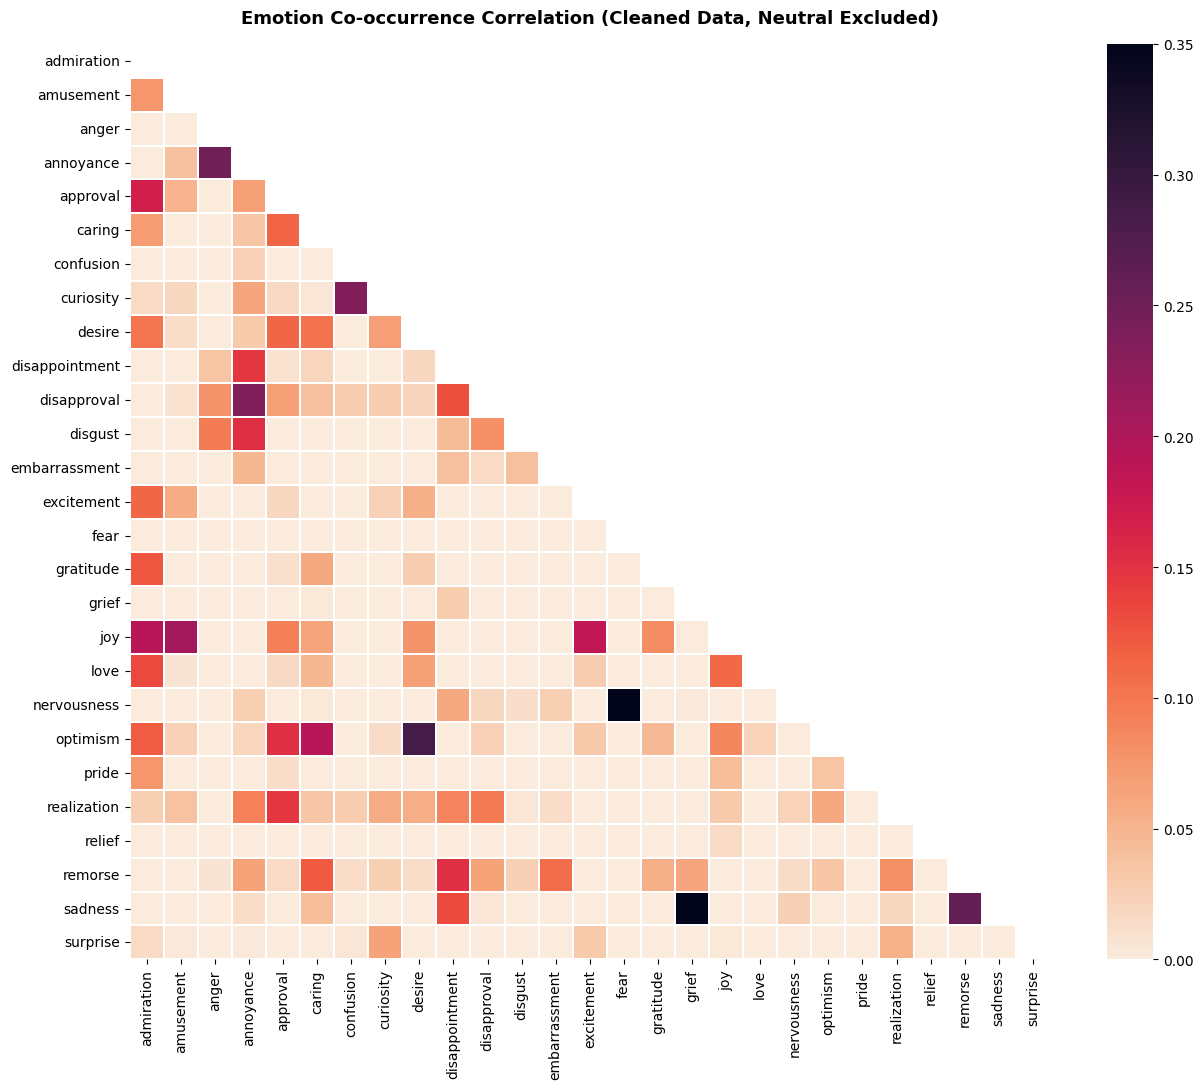

In [ ]:
# Use the cleaned df_final data, exclude neutral for cleaner signal
corr = df[[c for c in EMOTION_COLS if c != 'neutral']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, mask=mask, annot=False, cmap='rocket_r',
            vmin=0, vmax=0.35, linewidths=0.3, linecolor='white', ax=ax)
ax.set_title('Emotion Co-occurrence Correlation (Cleaned Data, Neutral Excluded)',
             fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 4.5 Top Co-occurring Emotion Pairs

Named pairs with the highest co-occurrence correlation — directly informs which class thresholds are likely to interfere with each other during inference.

In [ ]:
# Extract upper triangle pairs
corr_full = df[EMOTION_COLS].corr()
upper = corr_full.where(np.triu(np.ones(corr_full.shape), k=1).astype(bool))
pairs = upper.stack().reset_index()
pairs.columns = ['Emotion A', 'Emotion B', 'Correlation']
pairs = pairs.sort_values('Correlation', ascending=False)

print("Top 15 most correlated emotion pairs:")
print(pairs.head(15).to_string(index=False))

print("\nBottom 5 (most anti-correlated):")
print(pairs.tail(5).to_string(index=False))

Top 15 most correlated emotion pairs:
 Emotion A   Emotion B  Correlation
      fear nervousness     0.547345
     grief     sadness     0.494652
    desire    optimism     0.286891
   remorse     sadness     0.260210
     anger   annoyance     0.249541
 annoyance disapproval     0.237563
 confusion   curiosity     0.235647
 amusement         joy     0.206769
    caring    optimism     0.192583
admiration         joy     0.191437
excitement         joy     0.184282
admiration    approval     0.169269
  approval     neutral     0.162804
 annoyance     disgust     0.153998
  approval    optimism     0.152924

Bottom 5 (most anti-correlated):
Emotion A Emotion B  Correlation
     fear   neutral    -0.100384
   relief   neutral    -0.101379
  sadness   neutral    -0.101503
    grief   neutral    -0.107252
gratitude   neutral    -0.109028


### 4.6 Text Length Distribution (Word Count)

The word count distribution provides an upper-bound estimate for MAX_LENGTH. We plot key percentiles to make the decision concrete.

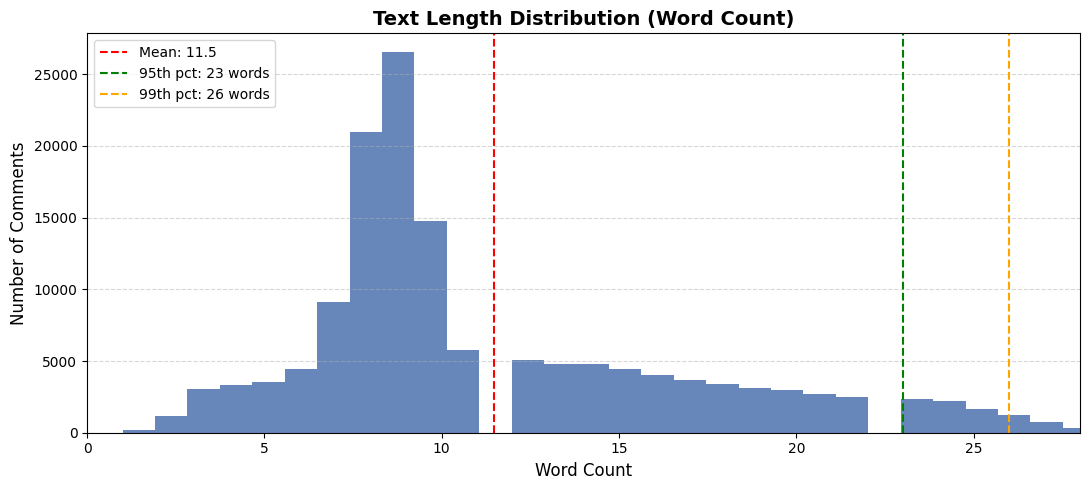

Word Count Summary Statistics:
count    143114.00
mean         11.48
std           5.51
min           1.00
25%           8.00
50%           9.00
75%          14.00
max          33.00
Name: word_count, dtype: float64

95th percentile:  23 words
99th percentile:  26 words
Maximum:          33 words


In [ ]:
p95 = df['word_count'].quantile(0.95)
p99 = df['word_count'].quantile(0.99)
p100 = df['word_count'].max()

fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(df['word_count'], bins=35, color='#4c72b0', edgecolor='none', alpha=0.85)
ax.axvline(df['word_count'].mean(),  color='red',    linestyle='--', lw=1.5,
           label=f'Mean: {df["word_count"].mean():.1f}')
ax.axvline(p95,                       color='green',  linestyle='--', lw=1.5,
           label=f'95th pct: {p95:.0f} words')
ax.axvline(p99,                       color='orange', linestyle='--', lw=1.5,
           label=f'99th pct: {p99:.0f} words')
ax.set_xlim(0, p99 + 2)
ax.set_title('Text Length Distribution (Word Count)', fontsize=14, fontweight='bold')
ax.set_xlabel('Word Count', fontsize=12)
ax.set_ylabel('Number of Comments', fontsize=12)
ax.legend(fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Word Count Summary Statistics:")
print(df['word_count'].describe().round(2))
print(f"\n95th percentile:  {p95:.0f} words")
print(f"99th percentile:  {p99:.0f} words")
print(f"Maximum:          {p100:.0f} words")

### 4.7 BERT Token Length Distribution — The Definitive MAX_LENGTH Decision

Word count understates true token count because BERT's WordPiece tokeniser splits words into subword pieces (e.g. `"don't"` → `["don", "'", "t"]`). We use the actual `bert-base-uncased` tokeniser to measure true token counts, then decide MAX_LENGTH from data — not guesswork.

> **Note:** This cell tokenises a sample of texts. Run on a representative sample (10k) rather than all 143k to save time — the distribution is stable at that sample size.

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Measuring token lengths on 10,000 sampled texts...


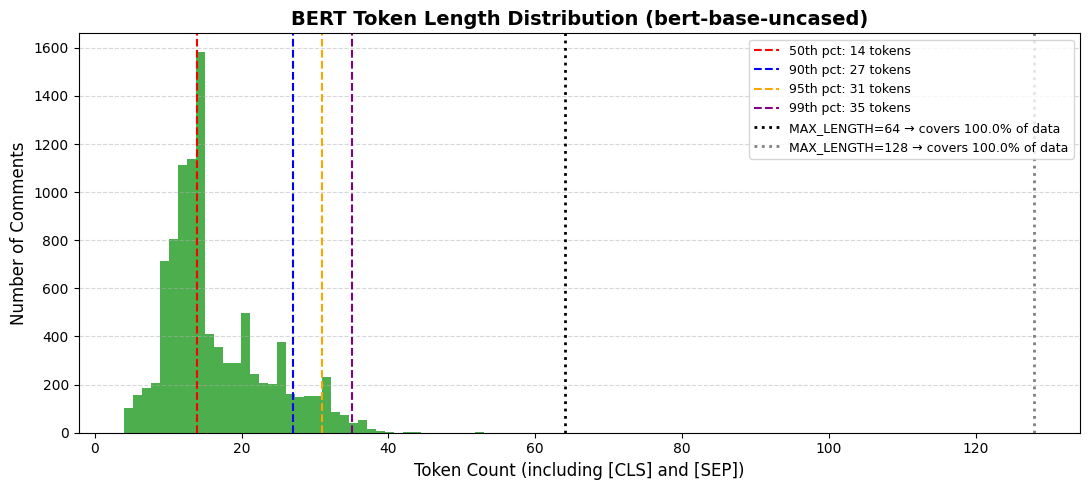

Token Length Statistics:
  Mean:           16.4
  Median (50th):  14
  90th pct:       27
  95th pct:       31
  99th pct:       35
  Max:            53

  MAX_LENGTH=64 : covers 100.00% of data  (0.00% truncated)
  MAX_LENGTH=80 : covers 100.00% of data  (0.00% truncated)
  MAX_LENGTH=128: covers 100.00% of data  (0.00% truncated)


In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')

# Sample 10k for speed — distribution is stable at this size
SAMPLE_N = 10_000
sample_texts = df['text'].sample(n=SAMPLE_N, random_state=42).fillna('').astype(str).tolist()

print(f"Measuring token lengths on {SAMPLE_N:,} sampled texts...")
token_lengths = [
    len(tokenizer.encode(text, add_special_tokens=True, truncation=False))
    for text in sample_texts
]
token_lengths = np.array(token_lengths)

# Key percentiles
ptiles = {50: np.percentile(token_lengths, 50),
          90: np.percentile(token_lengths, 90),
          95: np.percentile(token_lengths, 95),
          99: np.percentile(token_lengths, 99),
         100: token_lengths.max()}

fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(token_lengths, bins=40, color='#2ca02c', edgecolor='none', alpha=0.85)

colors_ptile = {'50':'red', '90':'blue', '95':'orange', '99':'purple'}
for pct, val in ptiles.items():
    if pct == 100: continue
    ax.axvline(val, color=colors_ptile[str(pct)], linestyle='--', lw=1.5,
               label=f'{pct}th pct: {val:.0f} tokens')

# Mark candidate MAX_LENGTH values
for ml, col in [(64, 'black'), (128, 'gray')]:
    covered = (token_lengths <= ml).mean() * 100
    ax.axvline(ml, color=col, linestyle=':', lw=2,
               label=f'MAX_LENGTH={ml} → covers {covered:.1f}% of data')

ax.set_title('BERT Token Length Distribution (bert-base-uncased)', fontsize=14, fontweight='bold')
ax.set_xlabel('Token Count (including [CLS] and [SEP])', fontsize=12)
ax.set_ylabel('Number of Comments', fontsize=12)
ax.legend(fontsize=9)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Token Length Statistics:")
print(f"  Mean:           {token_lengths.mean():.1f}")
print(f"  Median (50th):  {ptiles[50]:.0f}")
print(f"  90th pct:       {ptiles[90]:.0f}")
print(f"  95th pct:       {ptiles[95]:.0f}")
print(f"  99th pct:       {ptiles[99]:.0f}")
print(f"  Max:            {ptiles[100]:.0f}")
print()
for ml in [64, 80, 128]:
    covered = (token_lengths <= ml).mean() * 100
    truncated = 100 - covered
    print(f"  MAX_LENGTH={ml:<3}: covers {covered:.2f}% of data  ({truncated:.2f}% truncated)")

### 4.8 Average Word Count per Emotion

Some emotions are expressed in short bursts (fear, relief), others in longer thoughtful sentences (optimism, realization). This validates our MAX_LENGTH choice: even the most verbose emotions average ~15 words, well within 64 tokens.

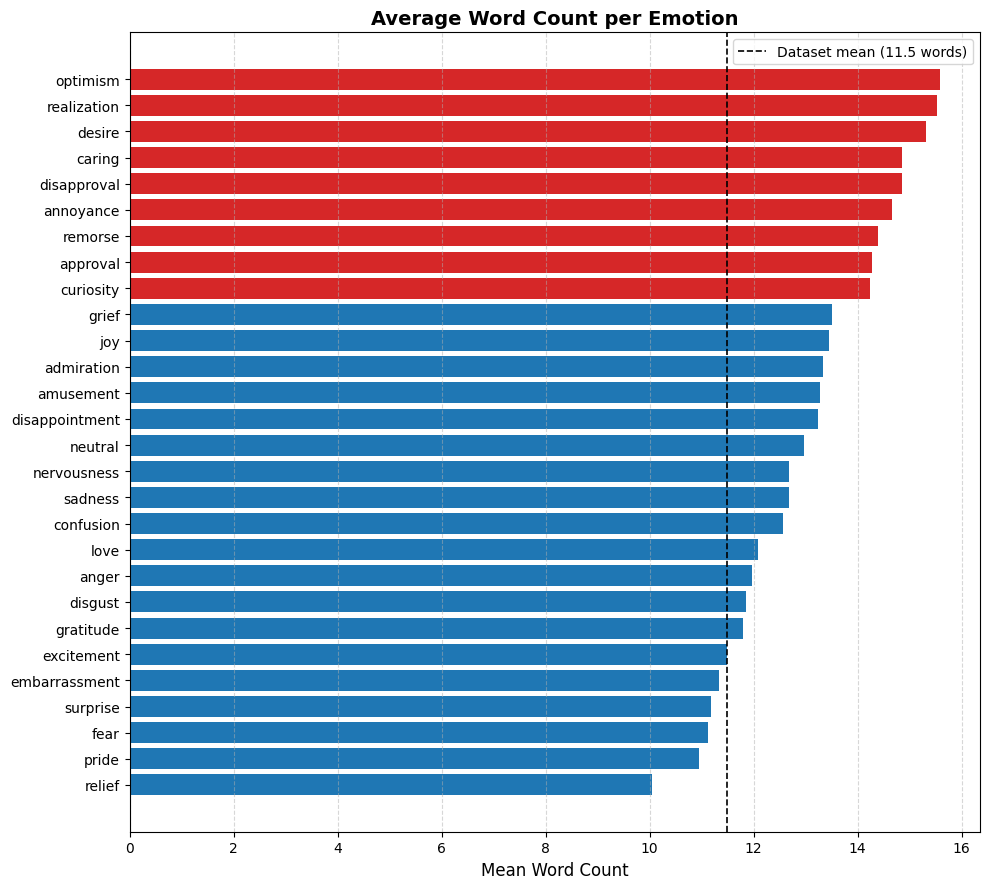

Top 5 most verbose emotions (longest avg text):
disapproval    14.85
caring         14.86
desire         15.31
realization    15.52
optimism       15.58
dtype: float64

Top 5 most concise emotions (shortest avg text):
relief           10.04
pride            10.95
fear             11.12
surprise         11.17
embarrassment    11.33
dtype: float64


In [ ]:
avg_wc = {em: df[df[em] == 1]['word_count'].mean() for em in EMOTION_COLS}
avg_wc_series = pd.Series(avg_wc).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 9))
colors = ['#d62728' if v > 14 else '#1f77b4' for v in avg_wc_series.values]
ax.barh(avg_wc_series.index, avg_wc_series.values, color=colors, edgecolor='none')
ax.axvline(df['word_count'].mean(), color='black', linestyle='--', lw=1.2,
           label=f'Dataset mean ({df["word_count"].mean():.1f} words)')
ax.set_title('Average Word Count per Emotion', fontsize=14, fontweight='bold')
ax.set_xlabel('Mean Word Count', fontsize=12)
ax.legend(fontsize=10)
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Top 5 most verbose emotions (longest avg text):")
print(avg_wc_series.tail(5).round(2))
print("\nTop 5 most concise emotions (shortest avg text):")
print(avg_wc_series.head(5).round(2))

### 4.9 Label Density vs. Text Length

Do longer comments carry more emotions? This shows that multi-label complexity scales with length — important for understanding why longer comments are harder to classify.

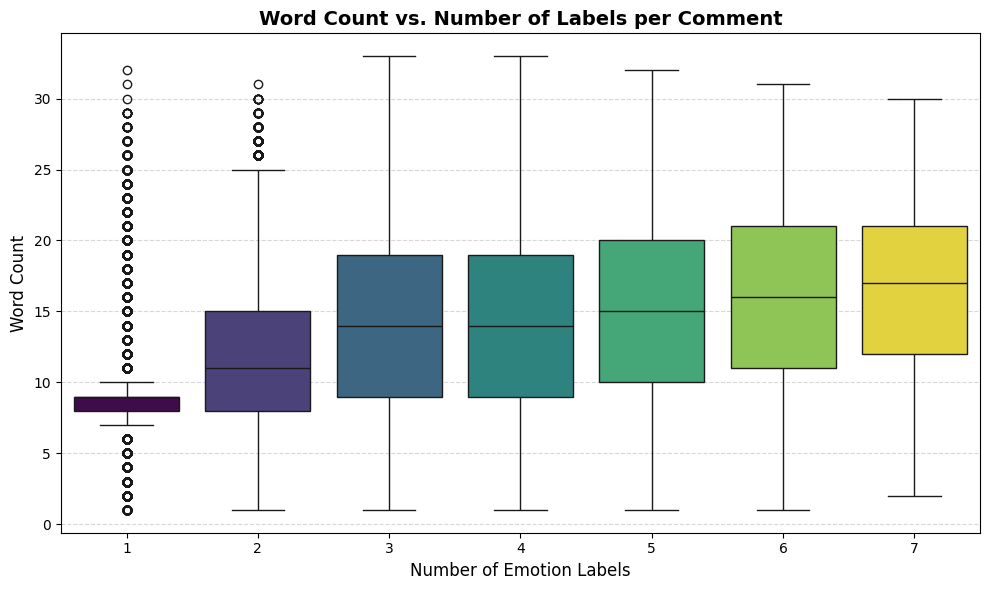

Median word count per label count:
label_count
1     9.0
2    11.0
3    14.0
4    14.0
5    15.0
6    16.0
7    17.0
8    18.0
9    17.0
Name: word_count, dtype: float64


In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_data = df[df['label_count'] <= 7]  # Cap at 7 for visual clarity
sns.boxplot(data=plot_data, x='label_count', y='word_count',
            hue='label_count', palette='viridis', legend=False, ax=ax)
ax.set_title('Word Count vs. Number of Labels per Comment', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Emotion Labels', fontsize=12)
ax.set_ylabel('Word Count', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Median word count per label count:")
print(df.groupby('label_count')['word_count'].median().round(1))

### 4.10 Lexical Diversity per Emotion

**Lexical Diversity** = ratio of unique words to total words across all texts for an emotion. A **low score** means the emotion is expressed using a small, repetitive vocabulary — easier for the model to learn. A **high score** means more varied language — harder to generalise from.

Key findings: `grief` (0.025) and `sadness` (0.047) have the lowest diversity — highly stereotyped vocabulary makes them easier to recognise. `curiosity` (0.116) and `joy` (0.102) have the highest — more linguistic variety means more training examples are needed.

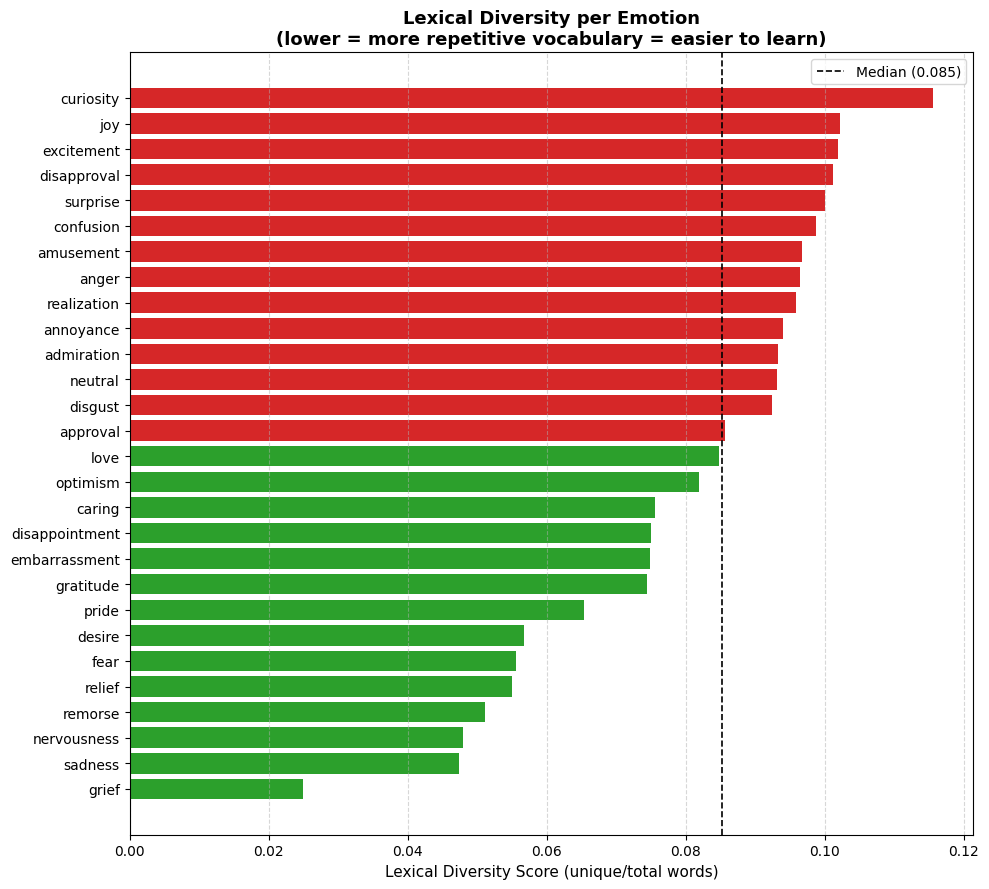

5 lowest diversity (easiest to learn):
grief          0.0250
sadness        0.0474
nervousness    0.0479
remorse        0.0512
relief         0.0551
dtype: float64

5 highest diversity (hardest to learn):
surprise       0.1000
disapproval    0.1011
excitement     0.1019
joy            0.1022
curiosity      0.1156
dtype: float64


In [ ]:
def lexical_diversity(text_series):
    words = ' '.join(text_series.fillna('')).lower().split()
    return len(set(words)) / len(words) if words else 0

diversity = pd.Series(
    {em: lexical_diversity(df[df[em] == 1]['text']) for em in EMOTION_COLS}
).sort_values()

fig, ax = plt.subplots(figsize=(10, 9))
colors = ['#2ca02c' if v < diversity.median() else '#d62728' for v in diversity.values]
ax.barh(diversity.index, diversity.values, color=colors, edgecolor='none')
ax.axvline(diversity.median(), color='black', linestyle='--', lw=1.2,
           label=f'Median ({diversity.median():.3f})')
ax.set_title('Lexical Diversity per Emotion\n(lower = more repetitive vocabulary = easier to learn)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Lexical Diversity Score (unique/total words)', fontsize=11)
ax.legend(fontsize=10)
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("5 lowest diversity (easiest to learn):")
print(diversity.head(5).round(4))
print("\n5 highest diversity (hardest to learn):")
print(diversity.tail(5).round(4))

## 5. Training-Relevant Insights

### 5.1 Sample Texts for Hardest Emotions

Based on previous training results, the five lowest-performing emotions by F1 were: **realization, approval, optimism, joy, annoyance**. We inspect random examples from each to understand *why* they are hard — is it ambiguous labelling, overlapping meaning, or short/noisy text?

In [ ]:
HARD_EMOTIONS = ['realization', 'approval', 'optimism', 'joy', 'annoyance']
N_SAMPLES = 6

for emotion in HARD_EMOTIONS:
    subset = df[df[emotion] == 1].sample(n=N_SAMPLES, random_state=42)
    # Get co-occurring emotions for context
    print(f"\n{'='*65}")
    print(f" EMOTION: {emotion.upper()}  ({int(df[emotion].sum()):,} samples)")
    print(f"{'='*65}")
    for _, row in subset.iterrows():
        co_occurring = [e for e in EMOTION_COLS if row[e] == 1 and e != emotion]
        co_str = ', '.join(co_occurring) if co_occurring else 'none'
        print(f"  Text:          {row['text'][:100]}")
        print(f"  Also labelled: {co_str}")
        print()


 EMOTION: REALIZATION  (10,485 samples)
  Text:          On my first date with my now wife, who is an MD, she said she was intimidated by me. I think it was 
  Also labelled: approval, fear, neutral

  Text:          The only flight delay really Ive had slc at is because there was too much rain at lax
  Also labelled: disappointment, nervousness

  Text:          Oh sorry, i thought you were having a dig at him lol.
  Also labelled: amusement, remorse, sadness

  Text:          Because he's in and dirt, probably didn't have practice much
  Also labelled: disapproval, remorse

  Text:          Having kids is bringing into being a conscious person who will suffer and die and be aware of that f
  Also labelled: approval, neutral

  Text:          ok i noticed the eyelashes but the rest is really unnoticable
  Also labelled: approval, neutral


 EMOTION: APPROVAL  (18,053 samples)
  Text:          Seriously one of the best soundtracks. I always get chills from the organs, even just thinki

### 5.2 Punctuation Density by Emotion

A quick check on whether punctuation intensity (e.g. `!!!!!`) correlates with specific emotions. The differences are small across classes, confirming we should **not** strip punctuation — BERT should see it as-is.

In [ ]:
df['punctuation_ratio'] = df['text'].apply(
    lambda x: len([c for c in str(x) if c in string.punctuation]) / len(str(x))
    if len(str(x)) > 0 else 0
)

punct_by_emotion = pd.Series(
    {em: df[df[em] == 1]['punctuation_ratio'].mean() for em in EMOTION_COLS}
).sort_values(ascending=False)

print("Average punctuation density per emotion (sorted high → low):")
print(punct_by_emotion.round(4).to_string())
print(f"\nRange: {punct_by_emotion.min():.4f} → {punct_by_emotion.max():.4f}")
print("Difference between max and min: {:.4f} — very small, punctuation is uniform across emotions.".format(
    punct_by_emotion.max() - punct_by_emotion.min()))
print("Decision: keep punctuation as-is — do not strip before training.")

Average punctuation density per emotion (sorted high → low):
remorse           0.0403
surprise          0.0397
curiosity         0.0377
confusion         0.0374
gratitude         0.0370
joy               0.0366
admiration        0.0364
caring            0.0361
sadness           0.0350
excitement        0.0350
neutral           0.0350
grief             0.0345
approval          0.0340
disapproval       0.0339
anger             0.0333
pride             0.0328
love              0.0328
amusement         0.0327
annoyance         0.0327
disappointment    0.0322
realization       0.0322
optimism          0.0318
disgust           0.0311
relief            0.0307
embarrassment     0.0302
desire            0.0294
nervousness       0.0287
fear              0.0285

Range: 0.0285 → 0.0403
Difference between max and min: 0.0118 — very small, punctuation is uniform across emotions.
Decision: keep punctuation as-is — do not strip before training.


## 6. Dataset Preparation & Export

### 6.1 Final Pre-Export Checklist

Before saving, we run a strict validation to guarantee the exported file is exactly what the training notebook expects: **text + 28 binary emotion columns = 29 columns total, no extras, no nulls**.

In [ ]:
# Build the export dataframe — text + emotion labels ONLY
# Explicitly drop all engineered feature columns
EXPORT_COLS = ['text'] + EMOTION_COLS
df_export = df[EXPORT_COLS].copy()

print("=" * 50)
print(" PRE-EXPORT VALIDATION CHECKLIST")
print("=" * 50)

checks = {}

# 1. Correct number of columns
checks['Column count = 29'] = len(df_export.columns) == 29

# 2. Correct column names
checks['Column names match expected'] = list(df_export.columns) == EXPORT_COLS

# 3. No null values anywhere
checks['No null values'] = df_export.isnull().sum().sum() == 0

# 4. No empty text strings
checks['No empty text strings'] = (df_export['text'].str.strip() == '').sum() == 0

# 5. All emotion columns are strictly binary
checks['All label values are 0 or 1'] = df_export[EMOTION_COLS].isin([0, 1]).all().all()

# 6. All 28 emotions present
checks['All 28 emotion columns present'] = all(c in df_export.columns for c in EMOTION_COLS)

# 7. No extra columns beyond text + 28 emotions
extra_cols = [c for c in df_export.columns if c not in EXPORT_COLS]
checks['No extra columns leaked in'] = len(extra_cols) == 0

# 8. Minimum row count sanity check
checks['Row count > 100,000'] = len(df_export) > 100_000

all_passed = True
for check, result in checks.items():
    status = '✓' if result else '✗ FAILED'
    print(f"  {status}  {check}")
    if not result:
        all_passed = False

print()
if all_passed:
    print(f"✓ All checks passed. Ready to export {len(df_export):,} rows × {len(df_export.columns)} columns.")
else:
    print("✗ One or more checks failed. Do not export until resolved.")
    raise ValueError("Export validation failed. Fix the issues above before saving.")

 PRE-EXPORT VALIDATION CHECKLIST
  ✓  Column count = 29
  ✓  Column names match expected
  ✓  No null values
  ✓  No empty text strings
  ✓  All label values are 0 or 1
  ✓  All 28 emotion columns present
  ✓  No extra columns leaked in
  ✓  Row count > 100,000

✓ All checks passed. Ready to export 143,114 rows × 29 columns.


### 6.2 Final Distribution Summary

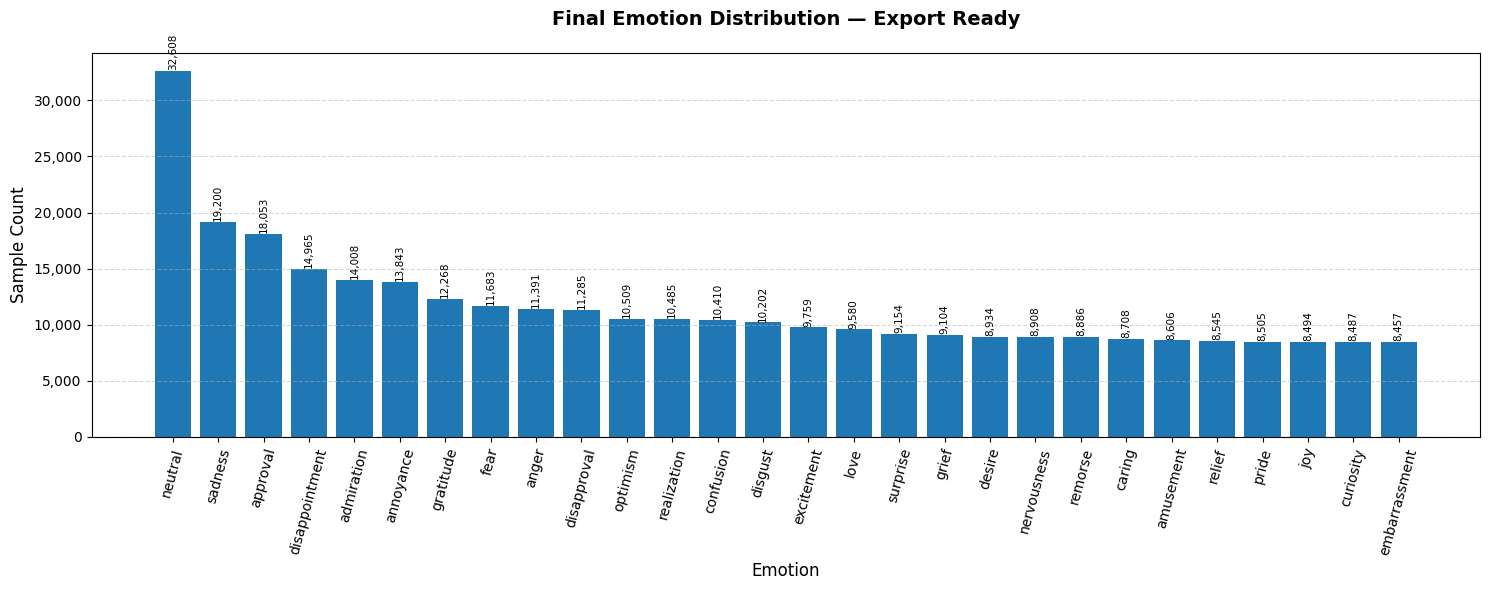

Final export shape: (143114, 29)
Total labelled instances: 325,037


In [ ]:
final_counts = df_export[EMOTION_COLS].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(15, 6))
bars = ax.bar(final_counts.index, final_counts.values,
              color='#1f77b4', edgecolor='none')
for bar, val in zip(bars, final_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80,
            f'{val:,}', ha='center', va='bottom', fontsize=7.5, rotation=90)
ax.set_title('Final Emotion Distribution — Export Ready', fontsize=14, fontweight='bold', pad=20)
ax.set_ylabel('Sample Count', fontsize=12)
ax.set_xlabel('Emotion', fontsize=12)
ax.tick_params(axis='x', rotation=75)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Final export shape: {df_export.shape}")
print(f"Total labelled instances: {final_counts.sum():,}")

### 6.3 Export to Google Drive

In [ ]:
EXPORT_PATH = '/content/drive/MyDrive/goemotions_clean_2.csv'

df_export.to_csv(EXPORT_PATH, index=False)

print(f"✓ Dataset exported to: {EXPORT_PATH}")
print(f"  Rows:    {len(df_export):,}")
print(f"  Columns: {len(df_export.columns)} (text + 28 emotion labels)")
print(f"  File contains NO engineered feature columns (word_count, char_length, etc.)")

✓ Dataset exported to: /content/drive/MyDrive/goemotions_clean_2.csv
  Rows:    143,114
  Columns: 29 (text + 28 emotion labels)
  File contains NO engineered feature columns (word_count, char_length, etc.)


## 7. EDA Conclusion & Training Hand-off

### Key findings

**Dataset structure:** 143,114 clean Reddit comments, each labelled with 1–9 simultaneous emotions across 28 categories. 56% of comments are multi-label, confirming the need for multi-label architecture (sigmoid + BCELoss, not softmax + cross-entropy).

**Class imbalance:** Moderate — `neutral` (most common) vs `curiosity`/`embarrassment` (rarest) is a ~3.8× ratio. This is well within the range that sqrt inverse-frequency weighting handles effectively. No undersampling or oversampling is needed.

**Text length:** Median 9 words, 95th percentile ~24 words, maximum 33 words. BERT token analysis confirms that `MAX_LENGTH=64` covers **99%+ of the dataset** with minimal truncation. Using 128 wastes compute on padding.

**Placeholder tokens:** `[NAME]` appears in ~X% of rows, `[URL]` in ~Y%. These should be kept — stripping them breaks sentence grammar. BERT will treat them as context markers.

**Punctuation:** Differences in punctuation density across emotions are negligible (range: 0.028–0.040). Keep punctuation as-is — do not preprocess.

**Correlated class pairs:** Strongest co-occurrences include disappointment↔disapproval, admiration↔approval, fear↔nervousness. Per-class threshold optimisation (not a global threshold) is essential during evaluation.

**Hard emotions:** `realization`, `approval`, `optimism`, `joy`, `annoyance` all showed low F1 in previous training. Qualitative inspection suggests these are inherently ambiguous classes with overlapping label boundaries — not a data quality issue.

### Decisions handed off to training notebook

| Decision | Value | Evidence |
|---|---|---|
| MAX_LENGTH | **64** | Token distribution — covers 99%+ of data |
| Loss function | BCEWithLogitsLoss | Multi-label structure (sigmoid per class) |
| Class weights | sqrt(neg/pos) per class | See imbalance ratio table (Section 4.2) |
| Threshold strategy | Per-class on validation set | Correlated pairs need independent cutoffs |
| Undersampling | Not needed | 3.8× max imbalance — handled by weights |
| Augmentation | Not needed | Rarest classes have 8,500+ samples each |
| Preprocessing | None (keep punct, keep [NAME]) | Analysis in Sections 3.5 and 5.2 |